# Header

In [1]:
from utils import *
import math
from scanpro import scanpro

In [2]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [3]:
os.chdir('../')

# Calc

In [4]:
meta = pd.read_csv('data/01_meta/meta_pt.csv', index_col=0)
meta

,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
sampleid,,,,,,,,,
9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS
30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,N,NHB-DCIS
119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,N,NHB-DCIS
28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [5]:
dat = sc.read_h5ad(
    'data/03_cleandata/ft_all.h5ad'
)

dat.obs.columns

Index(['nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts',
       'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA',
       'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score',
       'predicted.celltype.l1', 'predicted.celltype.l2.score',
       'predicted.celltype.l2', 'predicted.celltype.l3.score',
       'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8',
       'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score',
       'G2M.Score', 'Phase', 'celltype_level3'],
      dtype='object')

In [6]:
ct = pd.crosstab(dat.obs['predicted.celltype.l1'], 
                   dat.obs['dataset_name'])


pct = ct.div(ct.sum(axis=0))  #.sum(axis=0)

pct.index.name = None              # Remove the outer index name
pct.columns.name = None    

pct = pct.fillna(0) * 100
pct

,Pool137_6,Pool137_7,Pool137_8,Pool137_9,Pool137_10,Pool137_11,Pool137_12,Pool137_14,Pool137_15,Pool137_16,...,Pool138_19,Pool138_20,Pool138_21,Pool138_22,Pool138_23,Pool138_24,Pool138_25,Pool138_26,Pool138_27,Pool138_29
B,9.794202,15.872012,23.404527,12.026002,3.039308,4.916898,5.531258,12.055422,14.090431,14.299394,...,15.334302,4.325153,9.849040,11.694332,7.440236,13.162508,10.269533,6.589269,12.698413,22.390817
CD4 T,31.275349,33.969900,49.341348,51.648352,41.847900,43.732687,16.979676,44.043203,35.015773,41.398021,...,32.303779,37.407975,38.267624,35.681172,23.207091,27.673635,30.791539,27.251334,37.131519,47.710780
CD8 T,14.300736,15.682307,6.356312,5.943352,7.740105,18.732687,16.413687,10.560768,18.927445,8.027450,...,15.461483,10.889571,20.093800,18.857485,11.925866,27.120701,14.790174,6.369627,7.845805,13.788099
DC,1.667418,1.416466,1.138253,1.238198,2.688099,2.158356,2.778492,1.745581,1.892744,1.915097,...,2.670785,1.978528,2.594167,1.420667,4.217029,1.402562,1.774139,1.459052,1.575964,1.622905
Mono,27.174403,18.388769,14.439187,18.062219,29.785222,23.337950,47.671726,16.517565,22.712934,26.859240,...,29.087936,28.067485,20.342958,13.817856,46.360462,15.455158,38.348686,42.218387,22.913832,8.008972
NK,8.231936,9.649678,4.872746,10.818759,13.913278,5.170822,9.724723,12.633646,4.942166,6.240026,...,4.796512,17.331288,5.481460,13.668312,5.613752,9.723533,3.394746,15.531848,16.814059,6.425650
other T,7.555956,5.020868,0.447628,0.263117,0.986087,1.950600,0.900437,2.443814,2.418507,1.260772,...,0.345203,0.000000,3.370951,4.860176,1.235563,5.461902,0.631184,0.580483,1.020408,0.052777


In [7]:
pct_T = pct.T
pct_T.index.name = 'dataset_name'

pct_T_reset = pct_T.reset_index()
meta_reset = meta.reset_index()

ratio = pd.merge(pct_T_reset, meta_reset, on='dataset_name', how='inner') 
ratio

,dataset_name,B,CD4 T,CD8 T,DC,Mono,NK,other T,sampleid,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
0,Pool137_6,9.794202,31.275349,14.300736,1.667418,27.174403,8.231936,7.555956,6-H,1,94,HRL,NHW,71.1,N,Y,NHW-HRL
1,Pool137_7,15.872012,33.969900,15.682307,1.416466,18.388769,9.649678,5.020868,9-D,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS
2,Pool137_8,23.404527,49.341348,6.356312,1.138253,14.439187,4.872746,0.447628,54-D,1,87,DCIS,NHB,53.0,Y,N,NHB-DCIS
3,Pool137_9,12.026002,51.648352,5.943352,1.238198,18.062219,10.818759,0.263117,3145-H,1,84,HRL,NHB,58.9,Y,N,NHB-HRL
4,Pool137_10,3.039308,41.847900,7.740105,2.688099,29.785222,13.913278,0.986087,1-H,1,88,HRL,NHW,62.3,N,N,NHW-HRL
5,Pool137_11,4.916898,43.732687,18.732687,2.158356,23.337950,5.170822,1.950600,19-I,1,92,BC,NHW,48.0,N,N,NHW-BC
6,Pool137_12,5.531258,16.979676,16.413687,2.778492,47.671726,9.724723,0.900437,30-D,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
7,Pool137_14,12.055422,44.043203,10.560768,1.745581,16.517565,12.633646,2.443814,43-H,1,91,HRL,NHW,42.5,N,Y,NHW-HRL
8,Pool137_15,14.090431,35.015773,18.927445,1.892744,22.712934,4.942166,2.418507,45-I,1,91,BC,NHW,67.0,N,N,NHW-BC
9,Pool137_16,14.299394,41.398021,8.027450,1.915097,26.859240,6.240026,1.260772,56-I,1,92,BC,NHB,60.0,N,Y,NHB-BC


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.0

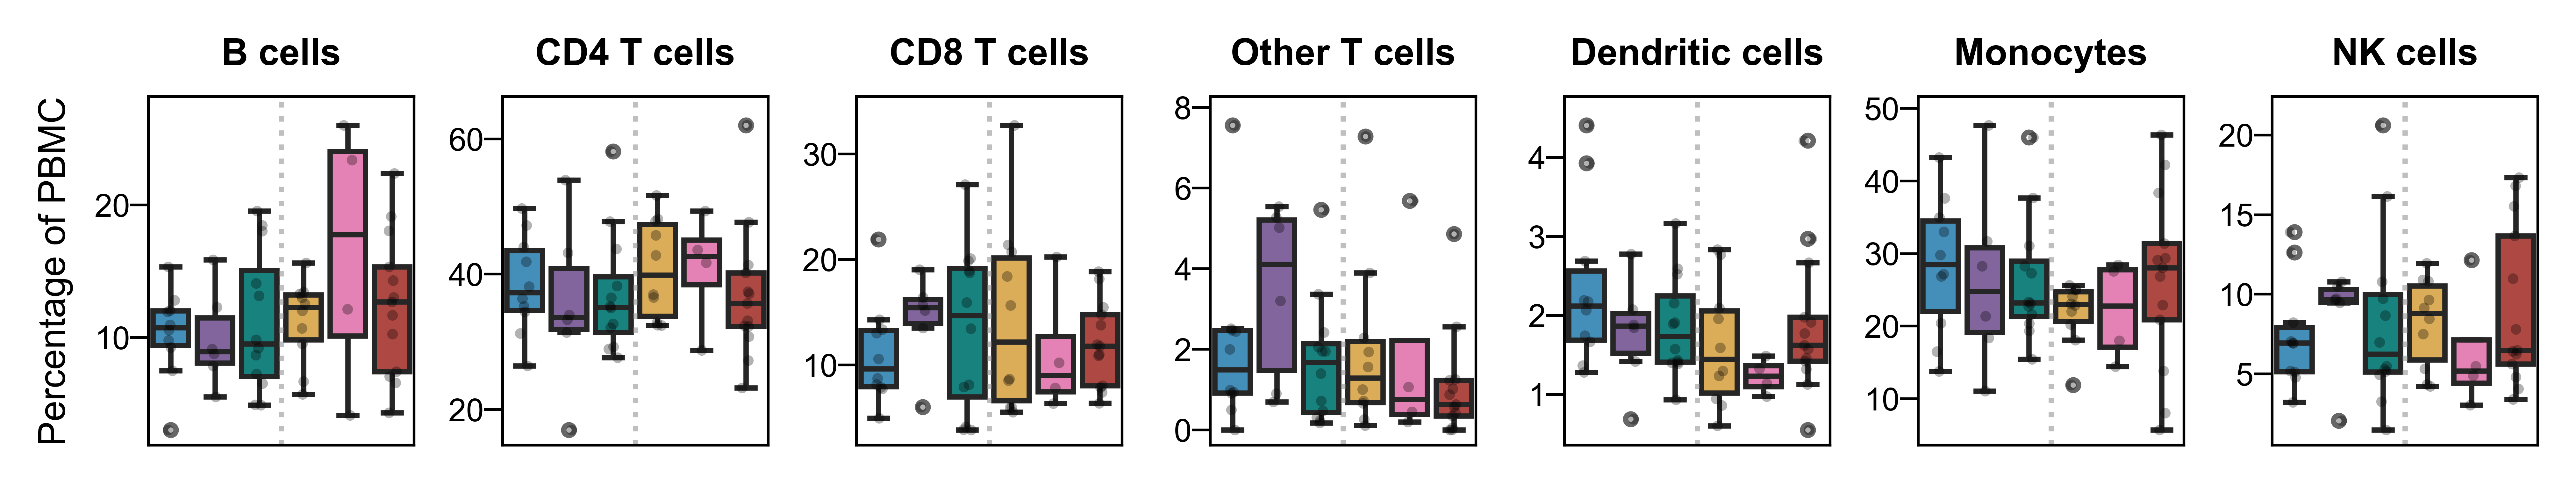

In [11]:
#test
from statannotations.Annotator import Annotator
from scipy.stats import f_oneway

dfp = ratio.copy()

dfp['race-stage'] = pd.Categorical(
    dfp['race-stage'],
    categories=['NHW-HRL','NHW-DCIS','NHW-BC', 
                'NHB-HRL','NHB-DCIS','NHB-BC'],
    ordered=True
    )

color_set = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830',

    'Diabetes':'navy',
    'Obesity':'salmon'

}






# Define the group for each pair (extract the trailing substring after '-' from NHW-HRL, etc.)
def get_race(pair):
    # E.g., ('NHB-HRL', 'NHB-DCIS') -> 'NHB'
    return pair[0].split('-')[0]

def get_comparison(pair):
    # E.g., ('NHB-DCIS', 'NHB-HRL') -> 'DCIS vs HRL'
    a = pair[0].split('-')[1]
    b = pair[1].split('-')[1]
    return f'{a} vs {b}'


def pval_to_star(p):
    # Customize as you wish (this is standard)
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

def get_group_from_celltype(celltype, cells_group):
    for group, members in cells_group.items():
        if celltype == members or celltype in members:
            return group
    return None

title_map = {
    'B': 'B cells',
    'CD4 T': 'CD4 T cells',
    'CD8 T': 'CD8 T cells',
    'other T': 'Other T cells',
    'DC': 'Dendritic cells',
    'Mono': 'Monocytes',
    'NK': 'NK cells'
}


# --------- Settings ---------

cells_ordered = ['B', 'CD4 T', 'CD8 T', 'other T', 'Mono', 'DC', 'NK']
ncol = 7
features = [x for x in cells_ordered if x in dfp.columns]#[x for x in cells_ordered if x in celltypes_sel]   # the cell type names
nrow = int(np.ceil(len(features)/ncol))
figwidth = 7
figheight = nrow * 1.3    # or adjust as needed

# ---- Figure layout (share y across panels) ----
fig, axs = plt.subplots(
    nrow, ncol,
    figsize=(figwidth, figheight)
)

axs = axs.flatten()
plt.subplots_adjust(left=0.1)

for i, yname in enumerate(features):
    ax = axs[i]

    sns.boxplot(
        data=dfp,
        x='race-stage',
        y=yname,
        hue='race-stage',
        palette=color_set,
        flierprops=dict(marker='o', markersize=2, alpha=0.7),
        showfliers=True,
        ax=ax
    )

    sns.stripplot(
        data=dfp,
        x='race-stage',
        y=yname,
        size=2,
        color='black',
        alpha=0.3,
        ax=ax
    )

    # vertical separator between NHW and NHB
    n_cat = dfp['race-stage'].nunique()
    split_x = n_cat / 2 - 0.5
    ax.axvline(
        x=split_x,
        linestyle=':',
        color='gray',
        alpha=0.5,
        linewidth=1
    )

    # ---- Statistical annotations ----
    pairs = [
        ('NHW-DCIS', 'NHW-HRL'), ('NHW-BC', 'NHW-DCIS'), ('NHW-BC', 'NHW-HRL'),
        ('NHB-DCIS', 'NHB-HRL'), ('NHB-BC', 'NHB-DCIS'), ('NHB-BC', 'NHB-HRL')
    ]

    annotator = Annotator(
        ax, pairs,
        data=dfp,
        x='race-stage',
        y=yname,
        perform_stat_test=False
    )

    annotator.configure(
        test='Mann-Whitney',
        text_format='star',
        loc='inside',
        hide_non_significant=True,
        comparisons_correction=None
    )
    annotator.apply_and_annotate()

    # ---- Axis formatting ----
    ax.set_title(
        title_map.get(yname, yname),
        fontsize=7,
        fontweight='bold'
    )
    ax.set_xlabel('')
    ax.set_xticklabels('')


    if i == 0:
        ax.set_ylabel('Percentage of PBMC', fontsize=7)
    else:
        ax.set_ylabel('')
        ax.tick_params(axis='y')

    ax.tick_params(axis='x', labelsize=6, rotation=90)
    ax.tick_params(axis='y', labelsize=6)

    ax.legend([], [], frameon=False)

# ---- Hide unused panels ----
for j in range(i + 1, len(axs)):
    axs[j].set_visible(False)

plt.tight_layout(rect=[0.04, 0.04, 1, 1])
plt.savefig('plots/F2/cellpctbox_mainLineage_stage.svg', dpi=600, bbox_inches='tight')

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.0

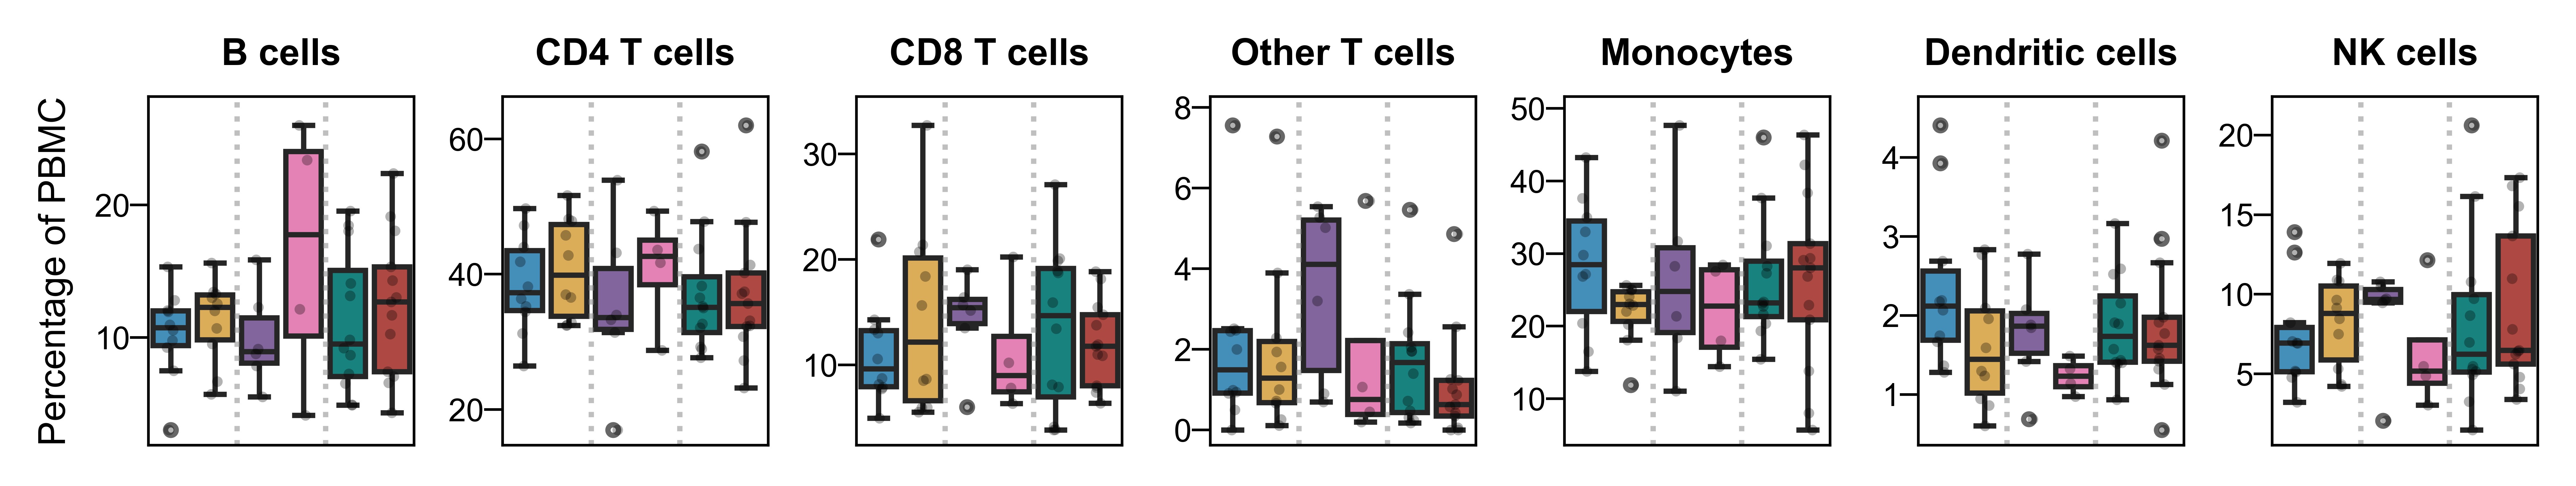

In [12]:
#test
from statannotations.Annotator import Annotator
from scipy.stats import f_oneway

dfp = ratio.copy()

dfp['race-stage'] = pd.Categorical(
    dfp['race-stage'],
    categories=['NHW-HRL','NHB-HRL',
                'NHW-DCIS','NHB-DCIS',
                'NHW-BC','NHB-BC'
                ],
    ordered=True
    )

color_set = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830',

    'Diabetes':'navy',
    'Obesity':'salmon'

}






# Define the group for each pair (extract the trailing substring after '-' from NHW-HRL, etc.)
def get_race(pair):
    # E.g., ('NHB-HRL', 'NHB-DCIS') -> 'NHB'
    return pair[0].split('-')[0]

def get_comparison(pair):
    # E.g., ('NHB-DCIS', 'NHB-HRL') -> 'DCIS vs HRL'
    a = pair[0].split('-')[1]
    b = pair[1].split('-')[1]
    return f'{a} vs {b}'


def pval_to_star(p):
    # Customize as you wish (this is standard)
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

def get_group_from_celltype(celltype, cells_group):
    for group, members in cells_group.items():
        if celltype == members or celltype in members:
            return group
    return None

title_map = {
    'B': 'B cells',
    'CD4 T': 'CD4 T cells',
    'CD8 T': 'CD8 T cells',
    'other T': 'Other T cells',
    'DC': 'Dendritic cells',
    'Mono': 'Monocytes',
    'NK': 'NK cells'
}


# --------- Settings ---------

cells_ordered = ['B', 'CD4 T', 'CD8 T', 'other T', 'Mono', 'DC', 'NK']
ncol = 7
features = [x for x in cells_ordered if x in dfp.columns]#[x for x in cells_ordered if x in celltypes_sel]   # the cell type names
nrow = int(np.ceil(len(features)/ncol))
figwidth = 7
figheight = nrow * 1.3    # or adjust as needed

# ---- Figure layout (share y across panels) ----
fig, axs = plt.subplots(
    nrow, ncol,
    figsize=(figwidth, figheight)
)

axs = axs.flatten()


for i, yname in enumerate(features):
    ax = axs[i]

    sns.boxplot(
        data=dfp,
        x='race-stage',
        y=yname,
        hue='race-stage',
        palette=color_set,
        flierprops=dict(marker='o', markersize=2, alpha=0.7),
        showfliers=True,
        ax=ax
    )

    sns.stripplot(
        data=dfp,
        x='race-stage',
        y=yname,
        size=2,
        color='black',
        alpha=0.3,
        ax=ax
    )

    # vertical separator between NHW and NHB
    n_cat = dfp['race-stage'].nunique()
    
    # boundaries for 2+2+2 split
    split_positions = [n_cat/3 - 0.5, 2*n_cat/3 - 0.5]  # 6 → [1.5, 3.5]
    
    for x in split_positions:
        ax.axvline(
            x=x,
            linestyle=':',
            color='gray',
            alpha=0.5,
            linewidth=1
        )

    # ---- Statistical annotations ----
    pairs = [
        ('NHW-HRL', 'NHB-HRL'),
        ('NHW-DCIS', 'NHB-DCIS'),
        ('NHW-BC', 'NHB-BC')
    ]

    annotator = Annotator(
        ax, pairs,
        data=dfp,
        x='race-stage',
        y=yname,
        perform_stat_test=False
    )

    annotator.configure(
        test='Mann-Whitney',
        text_format='star',
        loc='inside',
        hide_non_significant=True,
        comparisons_correction=None
    )
    annotator.apply_and_annotate()

    # ---- Axis formatting ----
    ax.set_title(
        title_map.get(yname, yname),
        fontsize=7,
        fontweight='bold'
    )
    ax.set_xlabel('')
    ax.set_xticklabels('')


    if i == 0:
        ax.set_ylabel('Percentage of PBMC', fontsize=7)
    else:
        ax.set_ylabel('')
        # ax.tick_params(axis='y', labelleft=False)

    ax.tick_params(axis='x', labelsize=6, rotation=90)
    ax.tick_params(axis='y', labelsize=6)

    ax.legend([], [], frameon=False)

# ---- Hide unused panels ----
for j in range(i + 1, len(axs)):
    axs[j].set_visible(False)

plt.tight_layout(rect=[0.04, 0.04, 1, 1])
plt.savefig('plots/F2/cellpctbox_mainLineage_race.svg', dpi=600, bbox_inches='tight')